In [18]:
import pandas as pd
import json
from bs4 import BeautifulSoup
from typing import List, Optional
from collections import namedtuple
from pydantic import BaseModel

First 10 days of sales data:
        Date        Sales
0 2018-01-01   713.649574
1 2018-01-02   718.711314
2 2018-01-03   806.873646
3 2018-01-04   905.887729
4 2018-01-05   911.229746
5 2018-01-06  1030.087178
6 2018-01-07  1000.468863
7 2018-01-08   728.514841
8 2018-01-09   699.454759
9 2018-01-10   800.421910

Summary statistics:
count    1826.000000
mean     1032.691117
std       321.269375
min         0.000000
25%       847.761834
50%       977.090214
75%      1145.505423
max      3410.327503
Name: Sales, dtype: float64


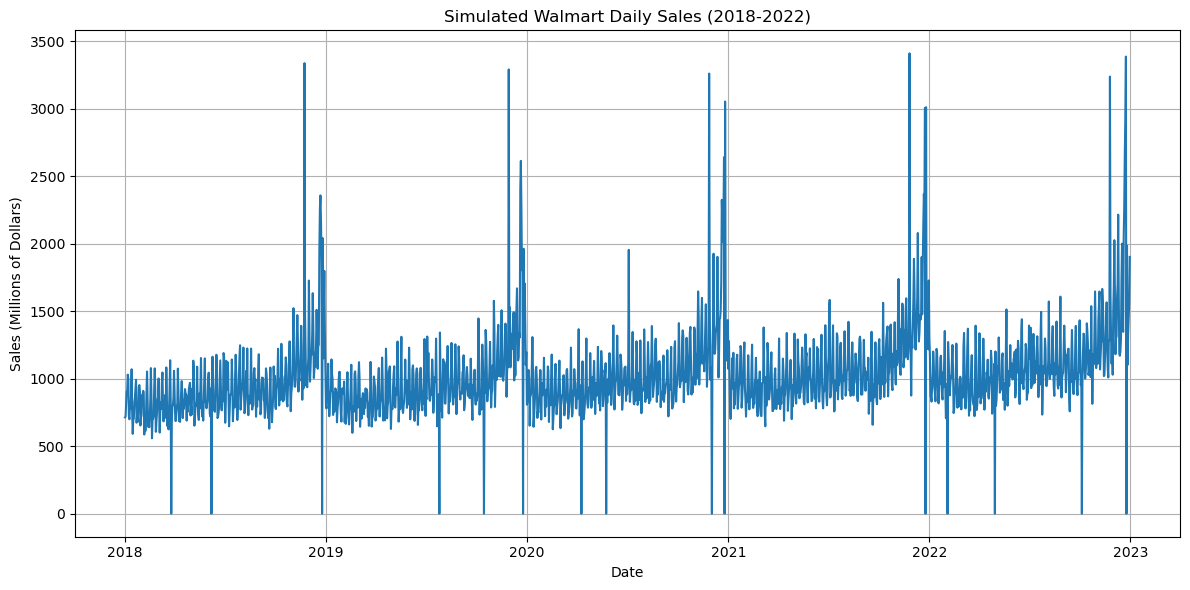

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)

# Define date range: 5 years of daily data
start_date = datetime(2018, 1, 1)
end_date = datetime(2022, 12, 31)
dates = pd.date_range(start=start_date, end=end_date, freq='D')

# Base sales (in millions of dollars)
base_sales = 850  # Average daily sales in millions

# 1. Long-term trend (gradual increase over years)
years = (dates.year - 2018).values
trend_factor = 1 + (years * 0.05)  # 5% annual growth

# 2. Monthly seasonality factors (based on retail patterns)
monthly_factors = {
    1: 0.95,   # January - post-holiday slump
    2: 0.90,   # February - low retail period
    3: 0.92,   # March - slight improvement
    4: 0.95,   # April - spring shopping
    5: 0.98,   # May - pre-summer
    6: 1.00,   # June - summer begins
    7: 1.02,   # July - summer shopping
    8: 1.05,   # August - back-to-school
    9: 1.00,   # September - post back-to-school
    10: 1.10,  # October - fall/halloween
    11: 1.25,  # November - holiday season begins
    12: 1.45   # December - peak holiday shopping
}

# 3. Day-of-week patterns (weekends are busier)
dow_factors = {
    0: 0.85,  # Monday
    1: 0.90,  # Tuesday
    2: 0.95,  # Wednesday
    3: 1.00,  # Thursday
    4: 1.15,  # Friday
    5: 1.30,  # Saturday
    6: 1.10   # Sunday
}

# 4. Special events (Black Friday, Christmas, etc.)
def special_event_factor(date):
    # Black Friday (4th Thursday of November + 1 day)
    if date.month == 11 and (date.day >= 23 and date.day <= 29) and date.weekday() == 4:
        return 2.5  # Extreme boost on Black Friday
    
    # Christmas Eve
    if date.month == 12 and date.day == 24:
        return 1.8
    
    # Christmas week (but closed on Christmas day)
    if date.month == 12 and date.day >= 20 and date.day <= 23:
        return 1.6
    
    # Day after Christmas
    if date.month == 12 and date.day == 26:
        return 1.7
    
    # Fourth of July
    if date.month == 7 and date.day == 4:
        return 1.4
    
    # Labor Day (first Monday in September)
    if date.month == 9 and date.day <= 7 and date.weekday() == 0:
        return 1.3
    
    # Memorial Day (last Monday in May)
    if date.month == 5 and date.day >= 25 and date.weekday() == 0:
        return 1.3
    
    # Normal day
    return 1.0

# 5. Random noise (variability in daily sales)
def random_noise():
    return np.random.normal(1, 0.08)  # 8% standard deviation

# Generate the sales data
sales_data = []
for i, date in enumerate(dates):
    # Skip Christmas day (store closed)
    if date.month == 12 and date.day == 25:
        sales = 0
    else:
        # Calculate all factors
        year_factor = trend_factor[i]
        month_factor = monthly_factors[date.month]
        dow_factor = dow_factors[date.weekday()]
        event_factor = special_event_factor(date)
        noise = random_noise()
        
        # Combine all factors
        sales = base_sales * year_factor * month_factor * dow_factor * event_factor * noise
    
    sales_data.append(sales)

# Create DataFrame
df = pd.DataFrame({
    'Date': dates,
    'Sales': sales_data
})

# Add some missing data points (store closures for weather, etc.)
# Select about 10 random days to set to 0 (besides Christmas)
closure_days = np.random.choice(len(df), 10, replace=False)
df.loc[closure_days, 'Sales'] = 0

# Display first few rows and summary statistics
print("First 10 days of sales data:")
print(df.head(10))
print("\nSummary statistics:")
print(df['Sales'].describe())

# Plot the data
plt.figure(figsize=(12, 6))
plt.plot(df['Date'], df['Sales'])
plt.title('Simulated Walmart Daily Sales (2018-2022)')
plt.xlabel('Date')
plt.ylabel('Sales (Millions of Dollars)')
plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns

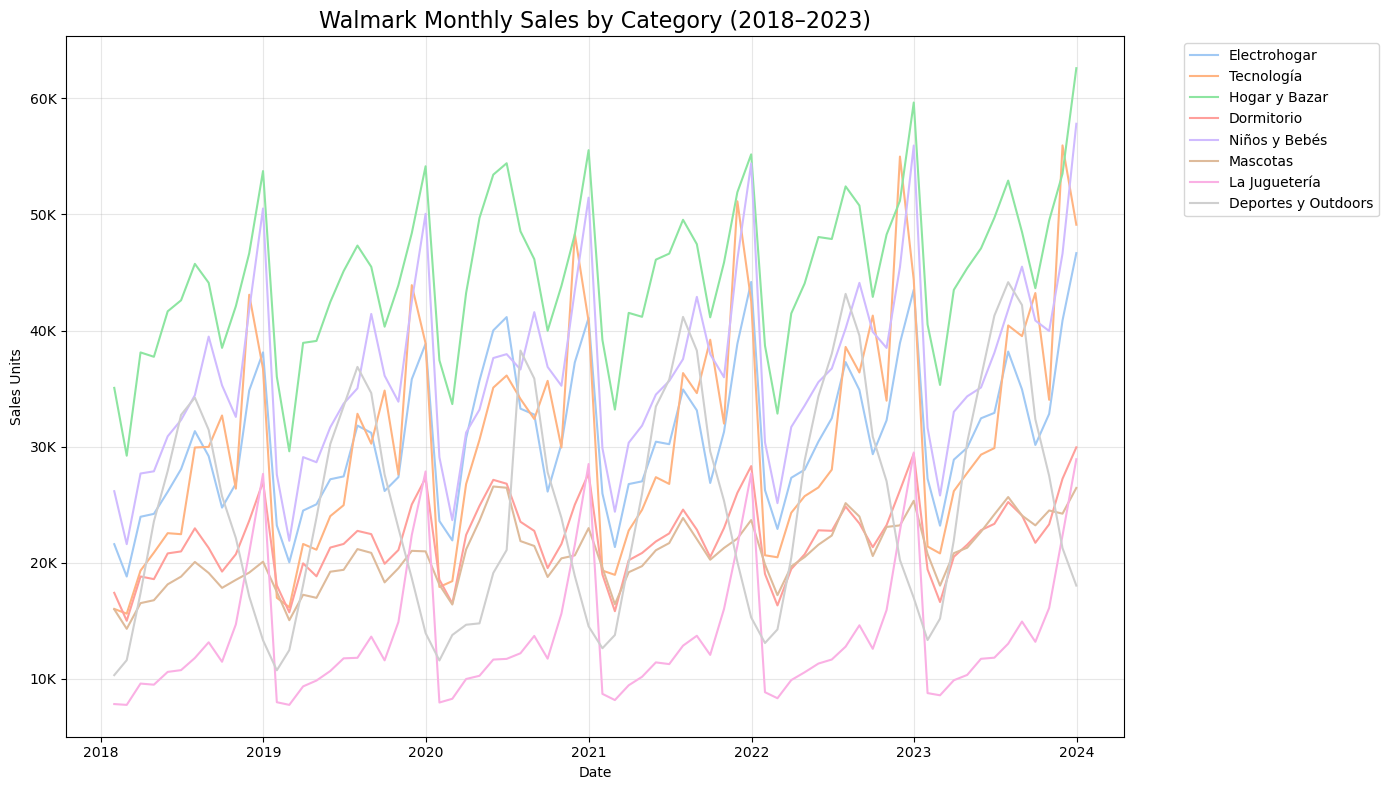

        date             category  sales
0 2018-01-01  Deportes y Outdoors    321
1 2018-01-01           Dormitorio    489
2 2018-01-01         Electrohogar    678
3 2018-01-01        Hogar y Bazar    958
4 2018-01-01        La Juguetería    236
5 2018-01-01             Mascotas    468
6 2018-01-01        Niños y Bebés    765
7 2018-01-01           Tecnología    487
8 2018-01-02  Deportes y Outdoors    298
9 2018-01-02           Dormitorio    521

Total records: 17528
Date range: 2018-01-01 00:00:00 to 2023-12-31 00:00:00


In [ ]:
# -------------------------------
# Parameters
# -------------------------------
START_DATE = '2018-01-01'
END_DATE = '2023-12-31'
SEED = 42
np.random.seed(SEED)

# Product categories
CATEGORIES = [
    'Electrohogar',        # Home appliances
    'Tecnología',          # Electronics
    'Hogar y Bazar',       # Home goods
    'Dormitorio',          # Bedroom
    'Niños y Bebés',       # Kids & Babies
    'Mascotas',            # Pets
    'La Juguetería',       # Toys
    'Deportes y Outdoors'  # Sports & Outdoors
]

# Base daily sales per category (relative size)
base_sales_per_category = {
    'Electrohogar': 800,
    'Tecnología': 700,
    'Hogar y Bazar': 1200,
    'Dormitorio': 600,
    'Niños y Bebés': 900,
    'Mascotas': 500,
    'La Juguetería': 400,
    'Deportes y Outdoors': 650
}

# Annual growth rate per category (e.g., tech grows faster)
growth_rate_per_category = {
    'Electrohogar': 0.04,
    'Tecnología': 0.06,
    'Hogar y Bazar': 0.03,
    'Dormitorio': 0.02,
    'Niños y Bebés': 0.035,
    'Mascotas': 0.05,  # Pet industry boomed
    'La Juguetería': 0.02,
    'Deportes y Outdoors': 0.05
}

# Monthly seasonality factors per category
monthly_factors = {
    'Electrohogar': {1:0.85, 2:0.80, 3:0.90, 4:0.95, 5:1.0, 6:1.05, 7:1.15, 8:1.10, 9:0.95, 10:1.0, 11:1.3, 12:1.4},
    'Tecnología':   {1:0.7, 2:0.75, 3:0.85, 4:0.90, 5:0.95, 6:1.0, 7:1.3, 8:1.25, 9:1.4, 10:1.1, 11:1.8, 12:1.5},
    'Hogar y Bazar':{1:0.9, 2:0.85, 3:0.95, 4:1.0, 5:1.05, 6:1.1, 7:1.15, 8:1.1, 9:1.0, 10:1.05,11:1.2, 12:1.3},
    'Dormitorio':   {1:0.9, 2:0.85, 3:0.95, 4:1.0, 5:1.05, 6:1.1, 7:1.15, 8:1.1, 9:1.0, 10:1.05,11:1.25,12:1.35},
    'Niños y Bebés':{1:0.9, 2:0.8, 3:0.95, 4:1.0, 5:1.05, 6:1.1, 7:1.15, 8:1.3, 9:1.2, 10:1.1, 11:1.4, 12:1.6},
    'Mascotas':     {1:1.0, 2:0.95, 3:1.0, 4:1.05, 5:1.1, 6:1.15, 7:1.2, 8:1.15, 9:1.05,10:1.1, 11:1.15,12:1.2},
    'La Juguetería':{1:0.6, 2:0.65, 3:0.7, 4:0.75, 5:0.8, 6:0.85, 7:0.9, 8:1.0, 9:0.9, 10:1.1, 11:1.6, 12:2.0},
    'Deportes y Outdoors':{1:0.5, 2:0.6, 3:0.8, 4:1.1, 5:1.3, 6:1.5, 7:1.6, 8:1.5, 9:1.2, 10:1.0, 11:0.8, 12:0.6}
}

# Weekly seasonality (same for all categories, but can be customized)
weekly_factors = {0:0.95, 1:0.95, 2:0.95, 3:0.98, 4:1.05, 5:1.3, 6:1.2}

# Promotions: e.g., every January, July, November
promotions = [
    ('01-15', 1.2, ['Hogar y Bazar', 'Dormitorio']),  # New Year Sale
    ('07-15', 1.25, ['Electrohogar', 'Tecnología']),  # Summer Tech Sale
    ('11-24', 1.5, ['Tecnología', 'La Juguetería']),  # Black Friday
]

# Pandemic effect (2020: Mar–Jun sharply down for some, up for others)
pandemic_start = pd.Timestamp('2020-03-15')
pandemic_end = pd.Timestamp('2020-06-30')

pandemic_impact = {
    'Electrohogar': 1.35,     # Increased (people at home)
    'Tecnología': 1.4,        # Laptops, webcams
    'Hogar y Bazar': 1.2,
    'Dormitorio': 1.25,
    'Niños y Bebés': 1.1,
    'Mascotas': 1.3,          # Pet adoption boom
    'La Juguetería': 1.05,    # Slight increase
    'Deportes y Outdoors': 0.6  # Gyms closed, less activity
}

# -------------------------------
# Create date range
# -------------------------------
dates = pd.date_range(start=START_DATE, end=END_DATE, freq='D')
n_days = len(dates)

# -------------------------------
# Prepare output list
# -------------------------------
data = []

for category in CATEGORIES:
    base_sales = base_sales_per_category[category]
    growth_rate = growth_rate_per_category[category]
    monthly_factor_dict = monthly_factors[category]

    # 1. Trend (exponential growth)
    years_since_start = (dates - dates[0]).days / 365.25
    trend = base_sales * (1 + growth_rate) ** years_since_start

    # 2. Monthly seasonality
    monthly_seasonality = np.array([monthly_factor_dict[month] for month in dates.month])

    # 3. Weekly seasonality
    weekly_seasonality = np.array([weekly_factors[day] for day in dates.weekday])

    # 4. Promotions
    promo_multiplier = np.ones(n_days)
    for month_day, mult, cats in promotions:
        if category in cats:
            mm, dd = map(int, month_day.split('-'))
            match = [(d.month == mm and d.day == dd) for d in dates]
            promo_multiplier[np.array(match)] = mult

    # 5. Pandemic effect
    pandemic_multiplier = np.ones(n_days)
    if category in pandemic_impact:
        during_pandemic = (dates >= pandemic_start) & (dates <= pandemic_end)
        pandemic_multiplier[during_pandemic] = pandemic_impact[category]

    # 6. Random noise
    noise = np.random.normal(loc=1.0, scale=0.1, size=n_days)

    # 7. Combine all
    sales = trend * monthly_seasonality * weekly_seasonality * promo_multiplier * pandemic_multiplier * noise
    sales = np.clip(sales, 100, None)  # Min sales
    sales = np.round(sales).astype(int)

    # Append to data
    for date, sale in zip(dates, sales):
        data.append({
            'date': date,
            'category': category,
            'sales': sale
        })

# Create DataFrame
df = pd.DataFrame(data)

# Convert date to datetime and sort
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['date', 'category']).reset_index(drop=True)

# Save to CSV
df.to_csv('walmark_historical_sales_by_category.csv', index=False)

# -------------------------------
# Plot: Total Sales Over Time by Category
# -------------------------------
plt.figure(figsize=(14, 8))
pivot = df.pivot_table(index='date', columns='category', values='sales', aggfunc='sum')
pivot_resampled = pivot.resample('M').sum()  # Monthly for clarity

# Use a nice color palette
colors = sns.color_palette("pastel", len(CATEGORIES))
for i, cat in enumerate(CATEGORIES):
    plt.plot(pivot_resampled.index, pivot_resampled[cat], label=cat, color=colors[i])

plt.title('Walmark Monthly Sales by Category (2018–2023)', fontsize=16)
plt.xlabel('Date')
plt.ylabel('Sales Units')

# Format y-axis as thousands
ax = plt.gca()
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x/1000)}K'))

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# -------------------------------
# Print sample
# -------------------------------
print(df.head(10))
print(f"\nTotal records: {len(df)}")
print(f"Date range: {df['date'].min()} to {df['date'].max()}")

In [57]:
import requests
from bs4 import BeautifulSoup
import re

In [63]:
def stock_data(name_file:str):
    with open(name_file) as file:
        html_file =file.read()
        soup = BeautifulSoup(html_file, 'html.parser')
        table = soup.find('table')
        headers = []
        rows_data = []
        # Extract headers (optional, if your table has a <thead> and <th>)
        header_row = table.find('tr') # Assuming the first row is the header
        if header_row:
            headers = [th.text.strip() for th in header_row.find_all('th')]
        # Extract data rows
        for row in table.find_all('tr')[1:]: # Skip the header row if already extracted
            cells = [td.text.strip() for td in row.find_all('td')]
            if cells: # Ensure the row is not empty
                rows_data.append(cells)
    df = pd.DataFrame(rows_data, columns=headers) # If headers were extracted
    df.index = pd.to_datetime(df['Date'], format="%b %d, %Y")
    df['Close   Close price adjusted for splits.'] = df['Close   Close price adjusted for splits.'].astype('float64')
    # df = df.set_index('DATE')
    
    column = re.search(r'[(](.+?)[)]',name_file).group(1)
    df_01 = df.rename(columns={'Close   Close price adjusted for splits.':column})
    return df_01[[column]].copy()

In [64]:
stocks = ['Walmart Inc. (WMT) Stock Historical Prices & Data - Yahoo Finance.html', 
          'ACM Research, Inc. (ACMR) Stock Historical Prices & Data - Yahoo Finance.html']
array = []
for stock in stocks:
    data = stock_data(stock)
    array.append(data)

In [79]:
de = (array[0].reset_index()).merge(array[1].reset_index(), on='Date',how='outer')

In [86]:
de_01 =de[~de.WMT.isnull()].copy()

In [108]:
de_01

,Date,WMT,ACMR
0,2025-09-02,97.85,27.58
1,2025-08-29,96.98,28.22
2,2025-08-28,96.11,29.29
3,2025-08-27,96.08,28.58
4,2025-08-26,96.05,29.91
...,...,...,...
1271,2020-09-10,45.60,20.22
1272,2020-09-09,46.63,20.03
1273,2020-09-08,46.15,19.66
1274,2020-09-04,47.61,27.36


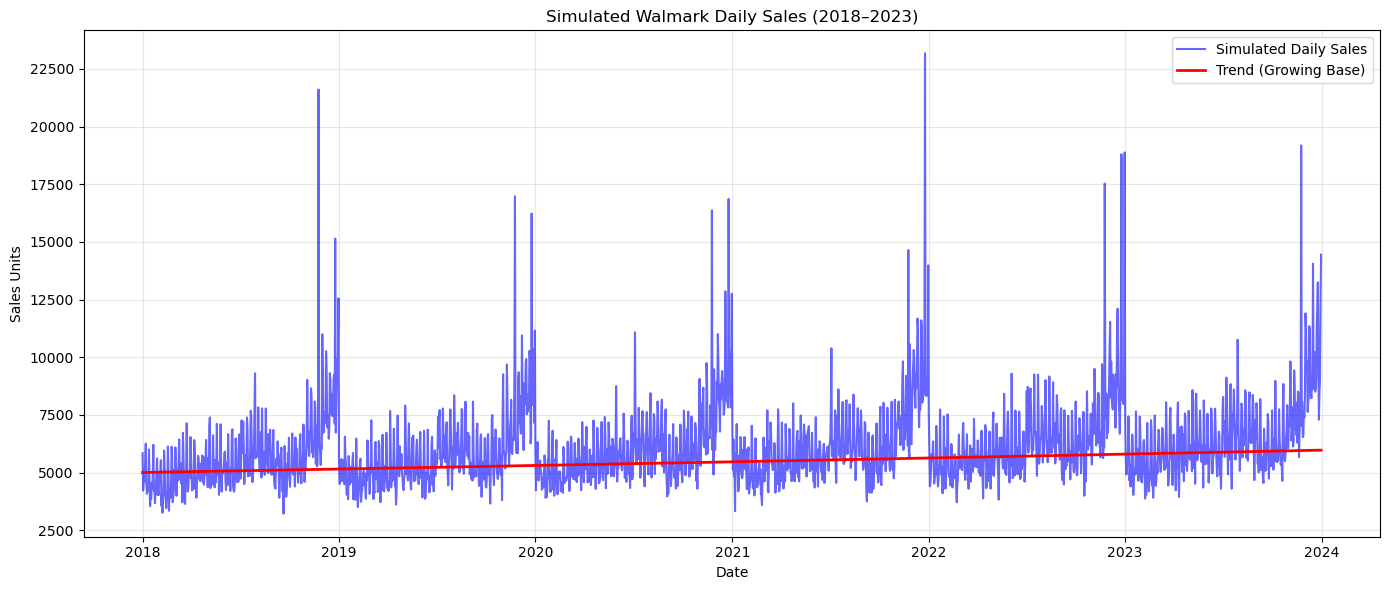

        date  sales
0 2018-01-01   5834
1 2018-01-02   4216
2 2018-01-03   4553
3 2018-01-04   5083
4 2018-01-05   4616
5 2018-01-06   5715
6 2018-01-07   6256
7 2018-01-08   4606
8 2018-01-09   4077
9 2018-01-10   4510


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# -------------------------------
# Parameters
# -------------------------------
START_DATE = '2018-01-01'
END_DATE = '2023-12-31'
BASE_DAILY_SALES = 5000  # Base average daily sales
GROWTH_RATE = 0.03       # Annual growth rate (3% per year)
SEED = 42
np.random.seed(SEED)

# Create date range
dates = pd.date_range(start=START_DATE, end=END_DATE, freq='D')
n_days = len(dates)

# -------------------------------
# 1. Base Trend (Exponential Growth)
# -------------------------------
years_since_start = (dates - dates[0]).days / 365.25
trend = BASE_DAILY_SALES * (1 + GROWTH_RATE) ** years_since_start

# -------------------------------
# 2. Seasonality
# -------------------------------

# Monthly seasonality (e.g., higher in Dec, lower in Feb)
month_factor = {
    1: 0.90,   # Jan - post-holiday dip
    2: 0.85,   # Feb - low
    3: 0.95,
    4: 0.95,
    5: 1.00,
    6: 0.95,
    7: 1.10,   # Summer peak
    8: 1.10,
    9: 0.95,
    10: 1.00,
    11: 1.20,  # Pre-holiday bump
    12: 1.50   # Christmas peak
}
monthly_seasonality = np.array([month_factor[month] for month in dates.month])

# Weekly seasonality (weekends higher)
day_of_week_factor = {
    0: 0.95,  # Monday
    1: 0.95,  # Tuesday
    2: 0.95,  # Wednesday
    3: 0.98,  # Thursday
    4: 1.05,  # Friday
    5: 1.30,  # Saturday - peak
    6: 1.20   # Sunday
}
weekly_seasonality = np.array([day_of_week_factor[day] for day in dates.weekday])

# -------------------------------
# 3. Holiday Effects
# -------------------------------
holiday_spikes = np.ones(n_days)
holidays = [
    ('12-25', 'Christmas', 2.0),
    ('11-24', 'BlackFriday', 2.5),  # Approx 4th Fri in Nov
    ('12-31', 'NewYearsEve', 1.6),
    ('07-04', 'IndependenceDay', 1.4),
    ('01-01', 'NewYearsDay', 1.3),
]

for month_day, name, multiplier in holidays:
    # Find matching dates (e.g., all Dec 25s)
    match = [(d.month, d.day) == tuple(map(int, month_day.split('-'))) for d in dates]
    holiday_spikes[np.array(match)] = multiplier

# -------------------------------
# 4. Random Noise
# -------------------------------
noise = np.random.normal(loc=1.0, scale=0.1, size=n_days)  # 10% std dev

# -------------------------------
# 5. Combine All Factors
# -------------------------------
sales = trend * monthly_seasonality * weekly_seasonality * holiday_spikes * noise

# Ensure no negative or zero sales
sales = np.clip(sales, 500, None)

# Round to whole numbers
sales = np.round(sales).astype(int)

# -------------------------------
# 6. Create DataFrame
# -------------------------------
df = pd.DataFrame({
    'date': dates,
    'sales': sales,
    'trend': trend,
    'monthly_factor': monthly_seasonality,
    'weekly_factor': weekly_seasonality,
    'holiday_multiplier': holiday_spikes
})

# Optional: Add store or region if needed (multi-store simulation)
# For now, this is total chain-wide daily sales

# -------------------------------
# 7. Save to CSV
# -------------------------------
# df[['date', 'sales']].to_csv('walmark_historical_sales.csv', index=False)

# -------------------------------
# 8. Plot
# -------------------------------
plt.figure(figsize=(14, 6))
plt.plot(df['date'], df['sales'], label='Simulated Daily Sales', color='blue', alpha=0.6)
plt.plot(df['date'], df['trend'], label='Trend (Growing Base)', color='red', linewidth=2)
plt.title('Simulated Walmark Daily Sales (2018–2023)')
plt.xlabel('Date')
plt.ylabel('Sales Units')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Display first few rows
print(df[['date', 'sales']].head(10))

Using device: cpu
Starting training...
Epoch 1/20: Loss: 0.6901, Accuracy: 55.94%
Epoch 2/20: Loss: 0.5065, Accuracy: 81.69%
Epoch 3/20: Loss: 0.2367, Accuracy: 90.12%
Epoch 4/20: Loss: 0.1817, Accuracy: 92.31%
Epoch 5/20: Loss: 0.1674, Accuracy: 93.25%
Epoch 6/20: Loss: 0.1405, Accuracy: 94.56%
Epoch 7/20: Loss: 0.1274, Accuracy: 94.62%
Epoch 8/20: Loss: 0.1138, Accuracy: 95.75%
Epoch 9/20: Loss: 0.1149, Accuracy: 95.38%
Epoch 10/20: Loss: 0.0877, Accuracy: 96.06%
Epoch 11/20: Loss: 0.0724, Accuracy: 97.38%
Epoch 12/20: Loss: 0.0828, Accuracy: 96.81%
Epoch 13/20: Loss: 0.0611, Accuracy: 97.94%
Epoch 14/20: Loss: 0.0600, Accuracy: 97.31%
Epoch 15/20: Loss: 0.0660, Accuracy: 97.44%
Epoch 16/20: Loss: 0.0449, Accuracy: 98.44%
Epoch 17/20: Loss: 0.0448, Accuracy: 98.44%
Epoch 18/20: Loss: 0.0435, Accuracy: 98.44%
Epoch 19/20: Loss: 0.0304, Accuracy: 99.06%
Epoch 20/20: Loss: 0.0304, Accuracy: 98.81%
Test Accuracy: 96.50%


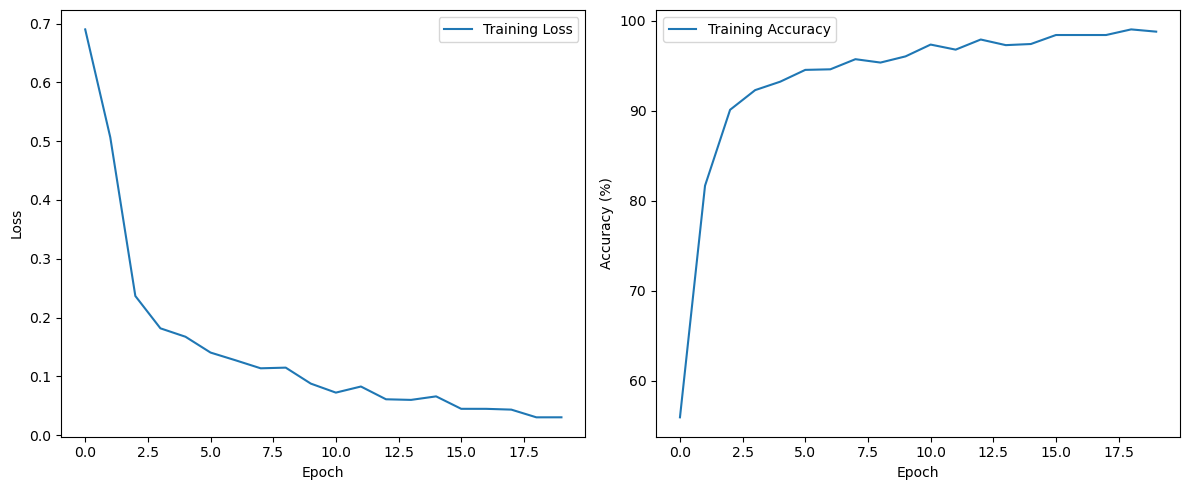

Model saved as concatenated_net.pth
Prediction probabilities: [[9.9996293e-01 3.7045687e-05]]
Actual class: 0


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt

# Generate synthetic data
def generate_synthetic_data(num_samples=1000):
    # Image-like data (28x28) for CNN
    images = torch.randn(num_samples, 1, 28, 28)
    
    # Tabular/feature data (10 features) for Feedforward network
    features = torch.randn(num_samples, 10)
    
    # Simple target: sum of image mean and features
    targets = (images.mean(dim=(1,2,3)) + features.mean(dim=1) > 0).long()
    
    return images, features, targets

# Define individual networks
class CNNBranch(nn.Module):
    def __init__(self):
        super(CNNBranch, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.3)
        
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.dropout(x)
        return x

class FeedforwardBranch(nn.Module):
    def __init__(self, input_size=10, hidden_size=32):
        super(FeedforwardBranch, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.dropout = nn.Dropout(0.3)
        
    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.relu(self.fc2(x))
        return x

# Combined network that concatenates both branches
class ConcatenatedNet(nn.Module):
    def __init__(self, cnn_branch, ff_branch, num_classes=2):
        super(ConcatenatedNet, self).__init__()
        self.cnn_branch = cnn_branch
        self.ff_branch = ff_branch
        
        # Calculate the combined feature size
        # CNN output: 32 channels * 7*7 (after two maxpool layers: 28->14->7)
        cnn_output_size = 32 * 7 * 7 
        ff_output_size = 32  # From FeedforwardBranch hidden_size
        
        self.classifier = nn.Sequential(
            nn.Linear(cnn_output_size + ff_output_size, 64),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(64, num_classes)
        )
        
    def forward(self, image_data, feature_data):
        # Process through CNN branch
        cnn_features = self.cnn_branch(image_data)
        cnn_features = cnn_features.view(cnn_features.size(0), -1)  # Flatten
        
        # Process through feedforward branch
        ff_features = self.ff_branch(feature_data)
        
        # Concatenate features from both branches
        combined_features = torch.cat((cnn_features, ff_features), dim=1)
        
        # Final classification
        output = self.classifier(combined_features)
        return output

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Hyperparameters
batch_size = 32
learning_rate = 0.001
num_epochs = 20

# Generate data
images, features, targets = generate_synthetic_data(2000)
dataset = TensorDataset(images, features, targets)

# Split into train and test
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
train_dataset, test_dataset = torch.utils.data.random_split(dataset, [train_size, test_size])

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Initialize models
cnn_branch = CNNBranch().to(device)
ff_branch = FeedforwardBranch().to(device)
model = ConcatenatedNet(cnn_branch, ff_branch).to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Training loop
train_losses = []
train_accuracies = []

print("Starting training...")
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for batch_idx, (image_batch, feature_batch, target_batch) in enumerate(train_loader):
        image_batch = image_batch.to(device)
        feature_batch = feature_batch.to(device)
        target_batch = target_batch.to(device)
        
        # Forward pass
        outputs = model(image_batch, feature_batch)
        loss = criterion(outputs, target_batch)
        
        # Backward pass and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        # Calculate accuracy
        _, predicted = outputs.max(1)
        total += target_batch.size(0)
        correct += predicted.eq(target_batch).sum().item()
        
        running_loss += loss.item()
    
    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100. * correct / total
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)
    
    print(f'Epoch {epoch+1}/{num_epochs}: Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.2f}%')

# Test the model
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for image_batch, feature_batch, target_batch in test_loader:
        image_batch = image_batch.to(device)
        feature_batch = feature_batch.to(device)
        target_batch = target_batch.to(device)
        
        outputs = model(image_batch, feature_batch)
        _, predicted = outputs.max(1)
        test_total += target_batch.size(0)
        test_correct += predicted.eq(target_batch).sum().item()

print(f'Test Accuracy: {100. * test_correct / test_total:.2f}%')

# Plot training history
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.tight_layout()
plt.show()

# Save the model
torch.save(model.state_dict(), 'concatenated_net.pth')
print("Model saved as concatenated_net.pth")

# Example of how to use the model for inference
def predict_example(model, image, features):
    model.eval()
    with torch.no_grad():
        image = image.unsqueeze(0).to(device)  # Add batch dimension
        features = features.unsqueeze(0).to(device)
        output = model(image, features)
        probabilities = F.softmax(output, dim=1)
        return probabilities.cpu().numpy()

# Test with a single example
test_image, test_features, test_target = test_dataset[0]
probs = predict_example(model, test_image, test_features)
print(f"Prediction probabilities: {probs}")
print(f"Actual class: {test_target}")

In [20]:
class Product(BaseModel):
    name: str
    description: Optional[str] = None
    price: float
    category: str
    image_url: Optional[str] = None
    stock_quantity:int
    is_available:bool 

In [29]:
ll = Product(
    name="susu",
description="susu",
price=50,
category="susu",
image_url="susu",
stock_quantity=10,
is_available=True
)

In [35]:
ll.dict()

{'name': 'susu',
 'description': 'susu',
 'price': 50.0,
 'category': 'susu',
 'image_url': 'susu',
 'stock_quantity': 10,
 'is_available': True}

In [28]:
([ll.model_dump(), ll.model_dump(), ll.model_dump()])

AttributeError: 'Product' object has no attribute 'model_dump'

In [6]:
html = "<h2><strong>Cocina de Pie Mabe con 4 hornillas</strong></h2>"
soup = BeautifulSoup(html)


print(soup.get_text())

Cocina de Pie Mabe con 4 hornillas


In [ ]:
with open("./dataset/scraping_data.json", "r") as scraping:
    data = json.load(scraping)

In [7]:
data[0][0][0].keys()
qq = BeautifulSoup(data[0][0][0]['Descripción'][0])

In [9]:
print(qq.get_text())

Cocina de Pie Mabe con 4 hornillas
Descubre la eficiencia y estilo que te ofrece la cocina de pie Mabe CMP6014AG0. Este modelo destaca por su elegante acabado en color grafito y ofrece una funcionalidad superior en tu cocina.
Especificaciones Técnicas

Número de hornillas: 4
Tipo de cocina: Gas
Capacidad del horno: 79 litros

Características Destacadas
La cocina de pie 4 hornillas Mabe CMP6014AG0 es ideal para preparar diversos platillos simultáneamente, optimizando tiempos y mejorando tu experiencia culinaria. 
Con un horno de gran capacidad, 79 litros, es perfecta para hornear, asar y calentar grandes cantidades de comida, lo que la convierte en un aliado indispensable para tus reuniones familiares o eventos especiales.
Ventajas de la Cocina Mabe de 4 Hornillas
Con un diseño robusto y fácil de limpiar, esta cocina de gas mejora el proceso de cocción y añade un toque de elegancia a tu cocina gracias a su acabado en grafito. 
Además, su tamaño compacto es ideal para cualquier espacio, 

<img src="https://blog.bismart.com/hs-fs/hubfs/Arquitectura_Medallion_Pasos.jpg?width=2631&height=984&name=Arquitectura_Medallion_Pasos.jpg">